# Tutorial 13: Denoising Auto Encoders



## Import Libraries

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets

import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


## Load Data Set



In [2]:
train_data = datasets.MNIST(root="./data", train=True, download=True)
test_data = datasets.MNIST(root="./data", train=False, download=True)

# normalize to 0-1 and add channel dimension
x_train = train_data.data.float().div(255.).unsqueeze(1)
x_test = test_data.data.float().div(255.).unsqueeze(1)

print("x_train:", x_train.shape)
print("x_test:", x_test.shape)
print("min/max:", x_train.min().item(), x_train.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 343kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.18MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.74MB/s]


x_train: torch.Size([60000, 1, 28, 28])
x_test: torch.Size([10000, 1, 28, 28])
min/max: 0.0 1.0


## Add Noise to the Images



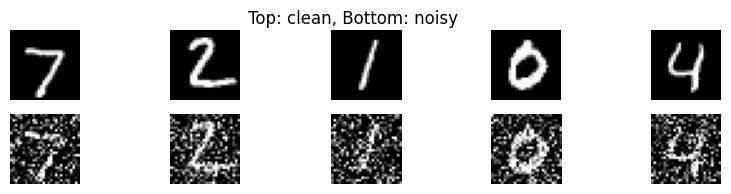

In [3]:
def add_noise(images, noise_factor=0.5):
    noisy_images = images + noise_factor * torch.randn_like(images)   # normal(0, 1) noise
    noisy_images = torch.clamp(noisy_images, 0., 1.)                  # keep values between 0 and 1
    return noisy_images

x_train_noisy = add_noise(x_train)
x_test_noisy = add_noise(x_test)

# data loaders: (noisy input, clean target)
BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(x_train_noisy, x_train), batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(TensorDataset(x_test_noisy, x_test), batch_size=BATCH_SIZE, shuffle=False)

# look at a few noisy images
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray"); plt.axis("off")
    plt.subplot(2, 5, i + 6)
    plt.imshow(x_test_noisy[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("Top: clean, Bottom: noisy")
plt.show()

## Build the Denoising Autoencoder



In [4]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        # encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        # decoder
        self.decoder = nn.Sequential(
            nn.Conv2d(64, 64, 3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2),
            nn.Conv2d(32, 1, 3, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

autoencoder = DenoisingAutoencoder().to(device)
print(autoencoder)

DenoisingAutoencoder(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (decoder): Sequential(
    (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Upsample(scale_factor=2.0, mode='nearest')
    (3): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): Upsample(scale_factor=2.0, mode='nearest')
    (6): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): Sigmoid()
  )
)


## Train the Autoencoder



In [5]:
EPOCHS = 10
LR = 1e-3

def train_autoencoder(model, epochs=EPOCHS, lr=LR):
    criterion = nn.BCELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for noisy, clean in train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            output = model(noisy)
            loss = criterion(output, clean)     # output vs the CLEAN image

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * noisy.size(0)
        train_loss = running / len(train_loader.dataset)

        # validation
        model.eval()
        running = 0.0
        with torch.no_grad():
            for noisy, clean in test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                running += criterion(model(noisy), clean).item() * noisy.size(0)
        test_loss = running / len(test_loader.dataset)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.4f} - val_loss: {test_loss:.4f}")
    return train_losses, test_losses

cnn_train_losses, cnn_test_losses = train_autoencoder(autoencoder)

Epoch 1/10 - loss: 0.1596 - val_loss: 0.1121
Epoch 2/10 - loss: 0.1092 - val_loss: 0.1050
Epoch 3/10 - loss: 0.1039 - val_loss: 0.1013
Epoch 4/10 - loss: 0.1013 - val_loss: 0.0995
Epoch 5/10 - loss: 0.0997 - val_loss: 0.0984
Epoch 6/10 - loss: 0.0986 - val_loss: 0.0972
Epoch 7/10 - loss: 0.0977 - val_loss: 0.0969
Epoch 8/10 - loss: 0.0970 - val_loss: 0.0960
Epoch 9/10 - loss: 0.0965 - val_loss: 0.0958
Epoch 10/10 - loss: 0.0961 - val_loss: 0.0955


## Visualize the Results



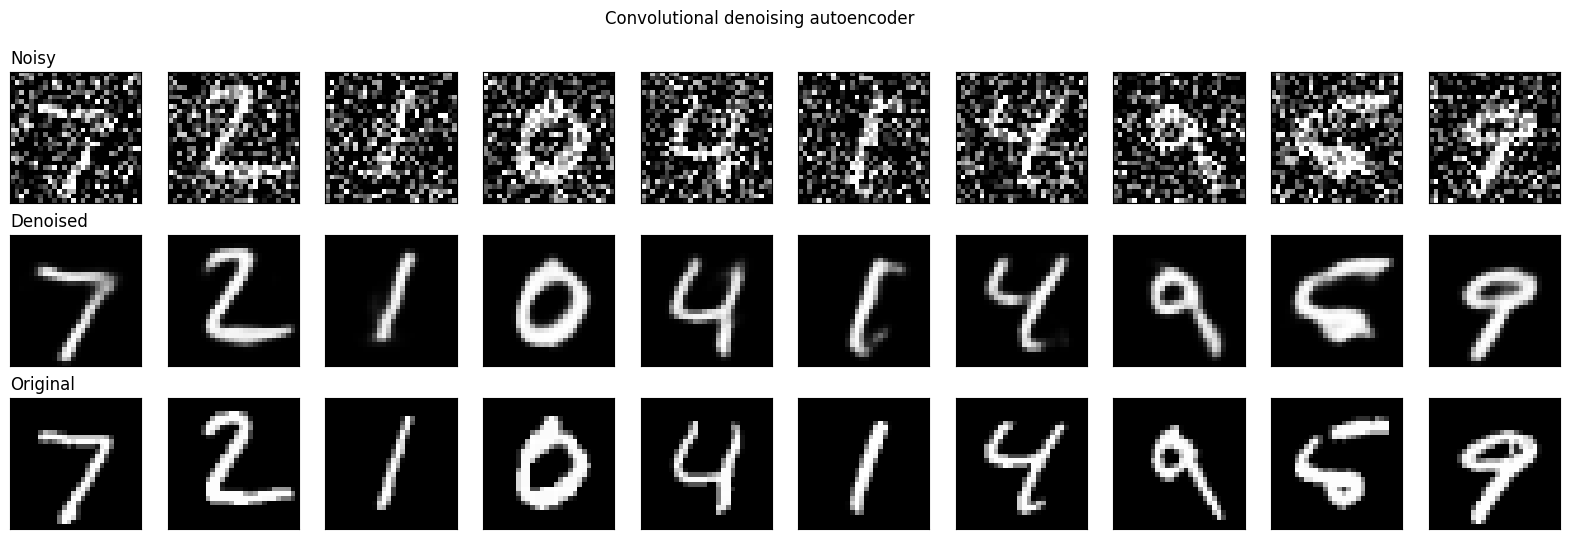

In [6]:
def get_output(model, x):
    # normal autoencoders return the image, VAE returns (image, mu, logvar)
    out = model(x)
    if isinstance(out, tuple):
        out = out[0]
    return out

def show_results(model, title="Denoising results", n=10):
    model.eval()
    noisy = x_test_noisy[:n].to(device)
    with torch.no_grad():
        decoded_imgs = get_output(model, noisy).cpu()

    plt.figure(figsize=(20, 6))
    for i in range(n):
        # noisy
        ax = plt.subplot(3, n, i + 1)
        plt.imshow(x_test_noisy[i].reshape(28, 28), cmap="gray")
        ax.get_xaxis().set_visible(False); ax.get_yaxis().set_visible(False)
        if i == 0: ax.set_title("Noisy", loc="left")

        # reconstructed
        ax = plt.subplot(3, n, i + 1 + n)
        plt.imshow(decoded_imgs[i].reshape(28, 28), cmap="gray")
        ax.get_xaxis().set_visible(False); ax.get_yaxis().set_visible(False)
        if i == 0: ax.set_title("Denoised", loc="left")

        # original
        ax = plt.subplot(3, n, i + 1 + 2 * n)
        plt.imshow(x_test[i].reshape(28, 28), cmap="gray")
        ax.get_xaxis().set_visible(False); ax.get_yaxis().set_visible(False)
        if i == 0: ax.set_title("Original", loc="left")
    plt.suptitle(title)
    plt.show()

show_results(autoencoder, title="Convolutional denoising autoencoder")

## Task 1: Deep Autoencoder



In [7]:
class DeepAutoencoder(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),                 # 1x28x28 -> 784
            nn.Linear(784, 512), nn.ReLU(),
            nn.Linear(512, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, latent_dim), nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 512), nn.ReLU(),
            nn.Linear(512, 784), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),  # back to an image
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

deep_ae = DeepAutoencoder().to(device)
print(deep_ae)
print("Parameters:", sum(p.numel() for p in deep_ae.parameters()))

DeepAutoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=512, bias=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=784, bias=True)
    (7): Sigmoid()
    (8): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)
Parameters: 1149520


Epoch 1/10 - loss: 0.2521 - val_loss: 0.2079
Epoch 2/10 - loss: 0.1819 - val_loss: 0.1675
Epoch 3/10 - loss: 0.1619 - val_loss: 0.1552
Epoch 4/10 - loss: 0.1500 - val_loss: 0.1466
Epoch 5/10 - loss: 0.1432 - val_loss: 0.1420
Epoch 6/10 - loss: 0.1375 - val_loss: 0.1367
Epoch 7/10 - loss: 0.1326 - val_loss: 0.1326
Epoch 8/10 - loss: 0.1288 - val_loss: 0.1305
Epoch 9/10 - loss: 0.1256 - val_loss: 0.1286
Epoch 10/10 - loss: 0.1230 - val_loss: 0.1265


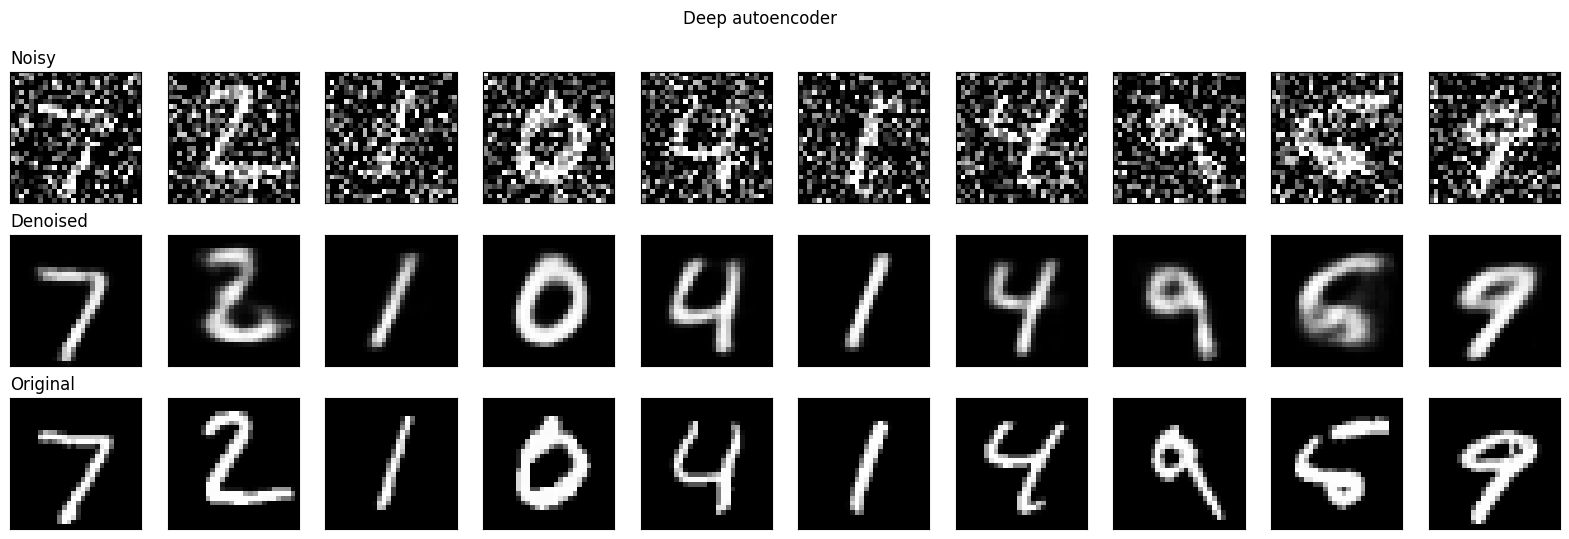

In [8]:
deep_train_losses, deep_test_losses = train_autoencoder(deep_ae)
show_results(deep_ae, title="Deep autoencoder")

## Task 2: Variational Autoencoder (VAE)



In [9]:
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.latent_dim = latent_dim

        # encoder: 28x28 -> 14x14 -> 7x7
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1),
            nn.ReLU(),
            nn.Flatten(),
        )
        self.fc_mu = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_logvar = nn.Linear(64 * 7 * 7, latent_dim)

        # decoder: latent -> 7x7 -> 14x14 -> 28x28
        self.fc_decode = nn.Linear(latent_dim, 64 * 7 * 7)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        return mu   # at test time just use the mean

    def decode(self, z):
        h = F.relu(self.fc_decode(z)).view(-1, 64, 7, 7)
        return self.decoder(h)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


def vae_loss(recon, target, mu, logvar):
    # reconstruction loss (summed over pixels)
    recon_loss = F.binary_cross_entropy(recon, target, reduction="sum")
    # KL divergence between N(mu, sigma^2) and N(0, 1)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl, recon_loss, kl


vae = VAE().to(device)
print(vae)

VAE(
  (encoder): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=3136, out_features=16, bias=True)
  (fc_logvar): Linear(in_features=3136, out_features=16, bias=True)
  (fc_decode): Linear(in_features=16, out_features=3136, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): Sigmoid()
  )
)


In [10]:
def train_vae(model, epochs=EPOCHS, lr=LR):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    train_losses, test_losses = [], []

    for epoch in range(epochs):
        model.train()
        running = 0.0
        for noisy, clean in train_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            recon, mu, logvar = model(noisy)
            loss, _, _ = vae_loss(recon, clean, mu, logvar)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item()
        train_loss = running / len(train_loader.dataset)    # loss per image

        model.eval()
        running = 0.0
        with torch.no_grad():
            for noisy, clean in test_loader:
                noisy, clean = noisy.to(device), clean.to(device)
                recon, mu, logvar = model(noisy)
                running += vae_loss(recon, clean, mu, logvar)[0].item()
        test_loss = running / len(test_loader.dataset)

        train_losses.append(train_loss)
        test_losses.append(test_loss)
        print(f"Epoch {epoch+1}/{epochs} - loss: {train_loss:.2f} - val_loss: {test_loss:.2f}")
    return train_losses, test_losses

vae_train_losses, vae_test_losses = train_vae(vae)

Epoch 1/10 - loss: 193.67 - val_loss: 132.63
Epoch 2/10 - loss: 132.58 - val_loss: 118.10
Epoch 3/10 - loss: 124.87 - val_loss: 114.25
Epoch 4/10 - loss: 121.61 - val_loss: 112.30
Epoch 5/10 - loss: 119.74 - val_loss: 111.17
Epoch 6/10 - loss: 118.57 - val_loss: 109.58
Epoch 7/10 - loss: 117.65 - val_loss: 109.44
Epoch 8/10 - loss: 116.92 - val_loss: 108.82
Epoch 9/10 - loss: 116.45 - val_loss: 108.78
Epoch 10/10 - loss: 115.97 - val_loss: 108.98


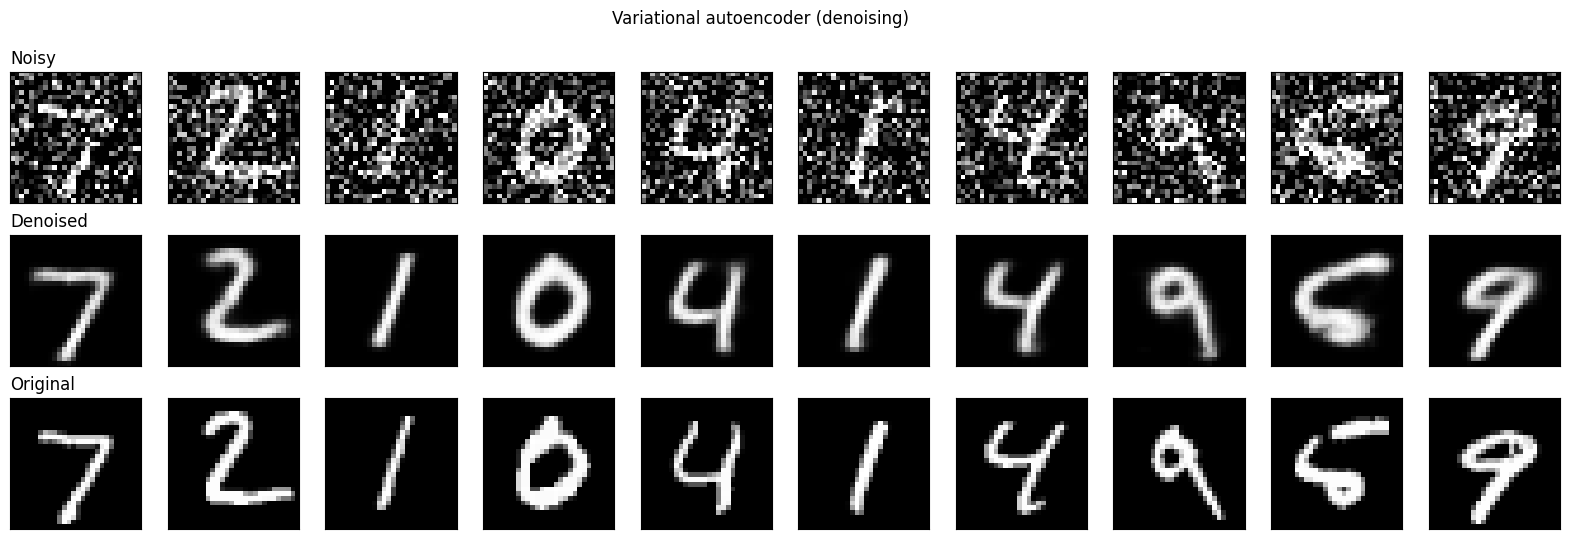

In [11]:
show_results(vae, title="Variational autoencoder (denoising)")

### Generating new digits with the VAE



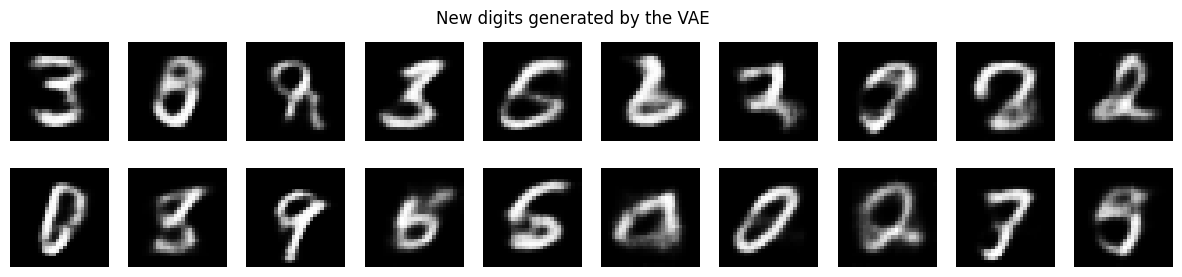

In [12]:
vae.eval()
with torch.no_grad():
    z = torch.randn(20, vae.latent_dim).to(device)
    generated = vae.decode(z).cpu()

plt.figure(figsize=(15, 3))
for i in range(20):
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(generated[i].reshape(28, 28), cmap="gray")
    ax.axis("off")
plt.suptitle("New digits generated by the VAE")
plt.show()

## Compare All Models

In [13]:
# same metric for every model: MSE between denoised output and clean image on the test set
def test_mse(model):
    model.eval()
    total = 0.0
    with torch.no_grad():
        for noisy, clean in test_loader:
            noisy, clean = noisy.to(device), clean.to(device)
            total += F.mse_loss(get_output(model, noisy), clean, reduction="sum").item()
    return total / (len(test_loader.dataset) * 28 * 28)

noisy_mse = F.mse_loss(x_test_noisy, x_test).item()
print(f"Noisy input (no model)     MSE: {noisy_mse:.5f}")
print(f"Conv denoising autoencoder MSE: {test_mse(autoencoder):.5f}")
print(f"Deep autoencoder           MSE: {test_mse(deep_ae):.5f}")
print(f"Variational autoencoder    MSE: {test_mse(vae):.5f}")

Noisy input (no model)     MSE: 0.11568
Conv denoising autoencoder MSE: 0.01083
Deep autoencoder           MSE: 0.02115
Variational autoencoder    MSE: 0.01590


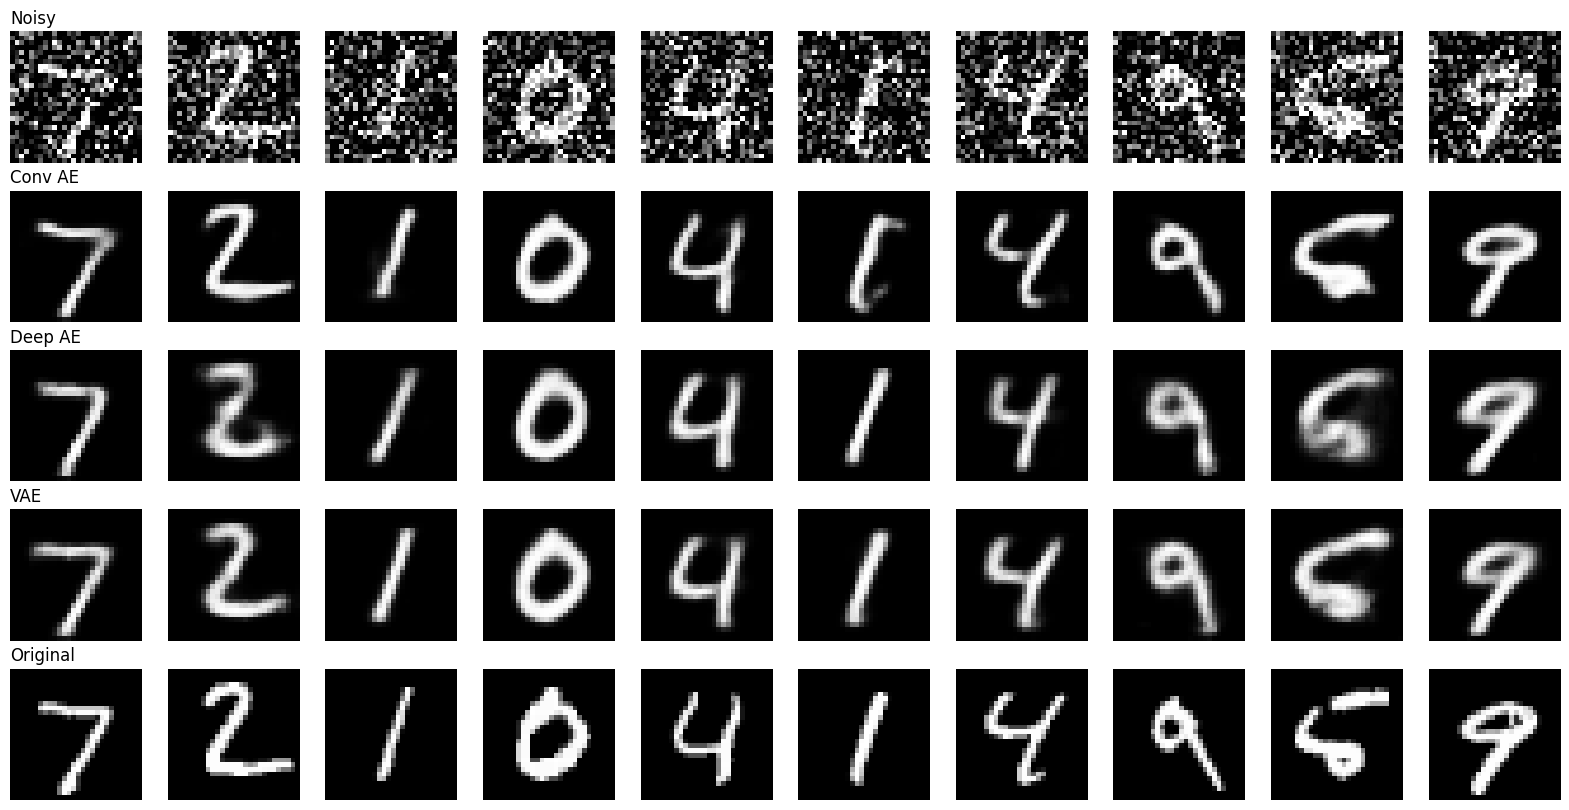

In [14]:
# all models side by side on the same images
n = 10
noisy = x_test_noisy[:n].to(device)
rows = [("Noisy", x_test_noisy[:n]), ("Conv AE", None), ("Deep AE", None), ("VAE", None), ("Original", x_test[:n])]
models = {"Conv AE": autoencoder, "Deep AE": deep_ae, "VAE": vae}

plt.figure(figsize=(20, 10))
for r, (name, data) in enumerate(rows):
    if data is None:
        m = models[name]; m.eval()
        with torch.no_grad():
            data = get_output(m, noisy).cpu()
    for i in range(n):
        ax = plt.subplot(len(rows), n, r * n + i + 1)
        plt.imshow(data[i].reshape(28, 28), cmap="gray")
        ax.axis("off")
        if i == 0: ax.set_title(name, loc="left")
plt.show()